# code_125 · Shared temporal models and a held-out sensor region

**Book:** section 24.5. A self-contained forecasting laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_24_GUIDE.md), [run evidence](../CHAPTER_24_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_125).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2725;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
import statsmodels
VERSIONS['statsmodels']=statsmodels.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2725


<a id="spatiotemporal-contract"></a>
 ## A known mesh does not make its missing regional measurements available
 Generate a moving-load response on twenty known one-dimensional locations for360hours. Only the first twelve locations supply historical sensor inputs or fitting labels; the rightmost eight locations are withheld from every fit. Their coordinates/topology are known, so this is a regional measurement/label holdout on a known structure, not an unseen-geometry claim. Source targets end before200, development targets before260, final targets before360; context8/horizons1/4/12, issue origins every4hours. Planned load position/amplitude are known future covariates. Compare a fixed-kernel spatial GP reference on declared location/load/horizon covariates, a shared node GRU and an actual graph-GRU that also receives previous neighbor hidden states. All models use training-only target transformations and development-only settings. Neural source training randomly masks20% of source measurements to expose the observation-mask contract; regional inputs remain always masked. Every window resets its recurrent hidden state.


,model,region,final_MSE,MSE_by_horizon,location_count,origin_count
0,Spatial GP,Source locations,0.001300,"[0.0015276548187621321, 0.001079501355078758, ...",12,23
1,Spatial GP,Held region,0.025818,"[0.023052279414590603, 0.024286189601856488, 0...",8,23
2,Shared temporal,Source locations,0.001332,"[0.0003900803406171053, 0.0010427556739425713,...",12,23
3,Shared temporal,Held region,0.057686,"[0.062064337461231425, 0.041082545667674955, 0...",8,23
4,Graph temporal,Source locations,0.002430,"[0.001071961563414453, 0.002510517323642494, 0...",12,23
5,Graph temporal,Held region,0.116564,"[0.036253596670628364, 0.048056339526190366, 0...",8,23


,family,distance_length_scale,development_source_MSE,rate,best_step
0,Spatial GP,0.12,0.001672,NaN,NaN
1,Spatial GP,0.25,0.001986,NaN,NaN
2,Shared temporal,NaN,0.002968,0.003,400.0
3,Shared temporal,NaN,0.001149,0.010,400.0
4,Graph temporal,NaN,0.002840,0.003,400.0
5,Graph temporal,NaN,0.002172,0.010,390.0


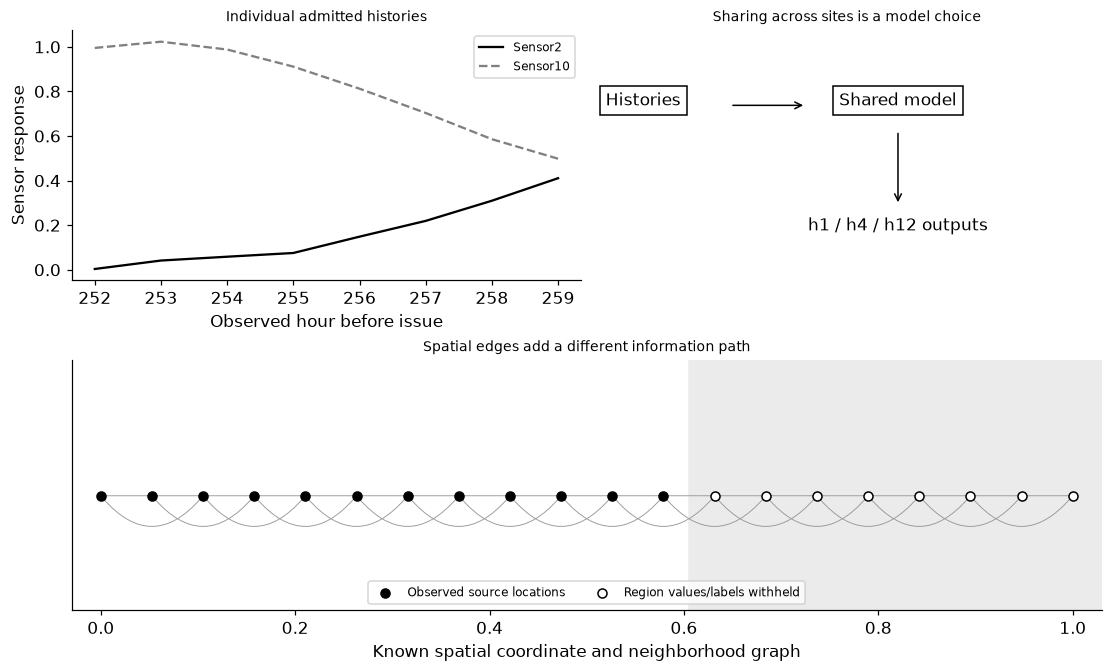

In [2]:
import copy
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF,WhiteKernel
from matplotlib.patches import Rectangle,FancyArrowPatch
N,T,L=20,360,8;positions=np.linspace(0,1,N);horizons=np.array([1,4,12]);clock=np.arange(T);load_position=.5+.42*np.sin(2*np.pi*clock/72);load_amplitude=1+.2*np.cos(2*np.pi*clock/120);distance=np.abs(positions[:,None]-positions[None,:]);covariance=.01**2*np.exp(-distance**2/(2*.12**2))+np.eye(N)*1e-10;factor=np.linalg.cholesky(covariance);state=np.zeros((T,N))
for t in range(1,T):
    target=load_amplitude[t]*np.exp(-(positions-load_position[t])**2/(2*.15**2));state[t]=.7*state[t-1]+.3*target+factor@rng.normal(size=N)
observed=state+rng.normal(0,.005,(T,N));source_nodes=np.arange(12);held_nodes=np.arange(12,20);adjacency=((distance>0)&(distance<=2.01/19)).astype(float);transition=adjacency/adjacency.sum(1,keepdims=True);p=torch.tensor(transition)
train_origins=np.arange(L,200-12+1,4);dev_origins=np.arange(200,260-12+1,4);final_origins=np.arange(260,T-12+1,4);training_mean=observed[:200,:12].mean();training_scale=observed[:200,:12].std();target_mean=training_mean;target_scale=training_scale
def windows(origins,training=False):
    histories=[];metadata=[];targets=[];masks=[]
    for origin in origins:
        mask=np.zeros((L,N));mask[:,:12]=1
        if training:mask[:,:12]*=rng.binomial(1,.8,(L,12))
        times=np.arange(origin-L,origin);value=(observed[times]-training_mean)/training_scale;value=value*mask;static=np.broadcast_to(2*positions-1,(L,N));relative=positions[None,:]-load_position[times,None];history=np.stack([value,mask,static,relative],axis=-1);future=origin+horizons-1;extra=np.concatenate([positions[:,None]-load_position[future][None,:],np.broadcast_to(load_amplitude[future],(N,3)),np.broadcast_to(horizons/12,(N,3))],axis=-1);histories.append(history);metadata.append(extra);targets.append(observed[future].T);masks.append(mask)
    return torch.tensor(np.array(histories)),torch.tensor(np.array(metadata)),torch.tensor((np.array(targets)-target_mean)/target_scale),np.array(masks)
tx,te,ty,tm=windows(train_origins,True);dx,de,dy,dm=windows(dev_origins);fx,fe,fy,fm=windows(final_origins);assert np.all(tm[:,:,12:]==0) and np.all(dm[:,:,12:]==0) and np.all(fm[:,:,12:]==0)
def gp_design(origins,nodes):
    rows=[]
    for origin in origins:
        for node in nodes:
            for horizon in horizons:
                future=origin+horizon-1;rows.append([positions[node]-load_position[future],positions[node]-load_position[origin-1],load_amplitude[future],horizon/12])
    return np.array(rows)
gp_train_x=gp_design(train_origins,source_nodes);gp_train_y=np.array([observed[o+h-1,node] for o in train_origins for node in source_nodes for h in horizons]);gp_dev_x=gp_design(dev_origins,source_nodes);gp_dev_y=np.array([observed[o+h-1,node] for o in dev_origins for node in source_nodes for h in horizons]);best=np.inf;candidates=[]
for ell in [.12,.25]:
    kernel=RBF([ell,ell,.5,1],length_scale_bounds='fixed')+WhiteKernel(.005,noise_level_bounds='fixed');model=GaussianProcessRegressor(kernel=kernel,optimizer=None,normalize_y=True,alpha=1e-8).fit(gp_train_x,gp_train_y);score=float(np.mean((model.predict(gp_dev_x)-gp_dev_y)**2));candidates.append({'family':'Spatial GP','distance_length_scale':ell,'development_source_MSE':score})
    if score<best:best=score;gp=model;selected_ell=ell
gp_prediction=gp.predict(gp_design(final_origins,np.arange(N))).reshape(len(final_origins),N,3);predictions={'Spatial GP':gp_prediction};complexity={'Spatial GP':{'source_training_rows':len(gp_train_x),'selected_distance_length_scale':selected_ell,'fixed_noise_variance_normalized':.005}}
class TemporalGraph(nn.Module):
    def __init__(self,graph):super().__init__();self.graph=graph;self.cell=nn.GRUCell(16 if graph else 4,12);self.head=nn.Sequential(nn.Linear(21,16),nn.ReLU(),nn.Linear(16,3))
    def forward(self,history,extra):
        batch,steps,nodes,_=history.shape;hidden=torch.zeros(batch,nodes,12,dtype=history.dtype)
        for step in range(steps):
            incoming=torch.cat([history[:,step],p@hidden],dim=-1) if self.graph else history[:,step];hidden=self.cell(incoming.reshape(-1,incoming.shape[-1]),hidden.reshape(-1,12)).reshape(batch,nodes,12)
        return self.head(torch.cat([hidden,extra],dim=-1))
fitted={}
for name,graph in [('Shared temporal',False),('Graph temporal',True)]:
    family_best=np.inf
    for rate in [.003,.01]:
        torch.manual_seed(SEED);model=TemporalGraph(graph);optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
        for step in range(1,401):
            model.train();optimizer.zero_grad();prediction=model(tx,te);loss=torch.mean((prediction[:,:12]-ty[:,:12])**2);loss.backward();optimizer.step()
            if step%10==0:
                model.eval()
                with torch.no_grad():score=float(torch.mean((model(dx,de)[:,:12]-dy[:,:12])**2))*target_scale**2
                if score<best:best=score;state_dict=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'family':name,'rate':rate,'development_source_MSE':best,'best_step':best_step})
        if best<family_best:family_best=best;chosen=(rate,best_step,state_dict)
    rate,best_step,state_dict=chosen;model.load_state_dict(state_dict);model.eval();fitted[name]=model
    with torch.no_grad():predictions[name]=model(fx,fe).numpy()*target_scale+target_mean
    complexity[name]={'parameters':sum(q.numel() for q in model.parameters()),'selected_rate':rate,'best_step':best_step,'update_limit':400}
truth=fy.numpy()*target_scale+target_mean;rows=[]
for name,prediction in predictions.items():
    for region,nodes in [('Source locations',source_nodes),('Held region',held_nodes)]:
        loss=np.mean((prediction[:,nodes]-truth[:,nodes])**2,axis=(0,1));rows.append({'model':name,'region':region,'final_MSE':float(loss.mean()),'MSE_by_horizon':loss.tolist(),'location_count':len(nodes),'origin_count':len(final_origins)})
# Poisoning unavailable regional values cannot alter an admitted input tensor.
raw_final=observed[final_origins[0]-L:final_origins[0]].copy();poison=raw_final.copy();poison[:,12:]+=1000;np.testing.assert_array_equal((poison-training_mean)/training_scale*fm[0],(raw_final-training_mean)/training_scale*fm[0]);assert gp_train_x.shape[0]==len(train_origins)*12*3 and train_origins.max()+12<=200 and dev_origins.max()+12<=260 and final_origins.max()+12<=T
RESULTS.update(comparisons=rows,candidates=candidates,complexity=complexity,horizons=horizons.tolist(),context_steps=L,source_location_indices=source_nodes.tolist(),held_location_indices=held_nodes.tolist(),known_geometry_locations=N,origin_counts=[len(train_origins),len(dev_origins),len(final_origins)],training_input_observation_fraction_on_source=float(tm[:,:,:12].mean()),region_measurements_used_for_fitting=False,region_measurements_used_as_inputs=False,region_coordinates_and_topology_known=True,unavailable_region_perturbation_changes_inputs=False,forecast_target='generated moving-load sensor response, not a field-validated PDE solver');display(pd.DataFrame(rows));display(pd.DataFrame(candidates))
fig=plt.figure(figsize=(10,6),layout='constrained');grid=fig.add_gridspec(2,2);axes=[fig.add_subplot(grid[0,0]),fig.add_subplot(grid[0,1]),fig.add_subplot(grid[1,:])];origin=int(final_origins[0]);times=np.arange(origin-L,origin)
for node,style in [(2,'-'),(10,'--')]:axes[0].plot(times,observed[times,node],style,color='black' if node==2 else '.5',label=f'Sensor{node}')
axes[0].set(xlabel='Observed hour before issue',ylabel='Sensor response',title='Individual admitted histories');axes[0].legend(fontsize=8)
ax=axes[1];ax.axis('off');ax.text(.1,.7,'Histories',transform=ax.transAxes,ha='center',bbox={'facecolor':'white','edgecolor':'black'});ax.text(.6,.7,'Shared model',transform=ax.transAxes,ha='center',bbox={'facecolor':'white','edgecolor':'black'});ax.text(.6,.2,'h1 / h4 / h12 outputs',transform=ax.transAxes,ha='center');ax.annotate('',xy=(.42,.7),xytext=(.27,.7),xycoords='axes fraction',arrowprops={'arrowstyle':'->'});ax.annotate('',xy=(.6,.3),xytext=(.6,.6),xycoords='axes fraction',arrowprops={'arrowstyle':'->'});ax.set_title('Sharing across sites is a model choice')
ax=axes[2]
for i,j in zip(*np.triu(adjacency,1).nonzero()):ax.add_patch(FancyArrowPatch((positions[i],0),(positions[j],0),arrowstyle='-',connectionstyle='arc3,rad=.6' if j-i>1 else 'arc3,rad=0',color='.6',linewidth=.6))
ax.scatter(positions[:12],np.zeros(12),c='black',s=35,label='Observed source locations');ax.scatter(positions[12:],np.zeros(8),facecolors='white',edgecolors='black',s=35,label='Region values/labels withheld');ax.axvspan((positions[11]+positions[12])/2,1.03,color='.92',zorder=0);ax.set(xlim=(-.03,1.03),ylim=(-.11,.13),yticks=[],xlabel='Known spatial coordinate and neighborhood graph',title='Spatial edges add a different information path');ax.legend(fontsize=8,ncol=2,loc='lower center');plt.show()


<a id="regional-forecast-limits"></a>
 ## Known structure, measured support and shared parameters are different resources
 The GP encodes a spatial/load/horizon covariance on declared summary inputs and receives no regional labels or observations. Neural models receive source sensor histories plus observation masks, coordinates and planned load metadata; their source loss excludes regional labels, and every window begins from zero hidden state. The graph model can propagate inferred hidden states through known unobserved nodes, but those states are not measurements. Its extra neighbor-state input also changes parameter count. Source training measurement dropout is declared; it is not evidence that a complete held region is interchangeable with independent missing values. Final errors separate temporal holdout at observed sites from the spatially withheld region. This tests a known geometry and scheduled load path, with no independent-structure, unseen-mesh or field-physics validity claim. Geostatistical covariance support and coordinate extrapolation remain assumptions to audit.


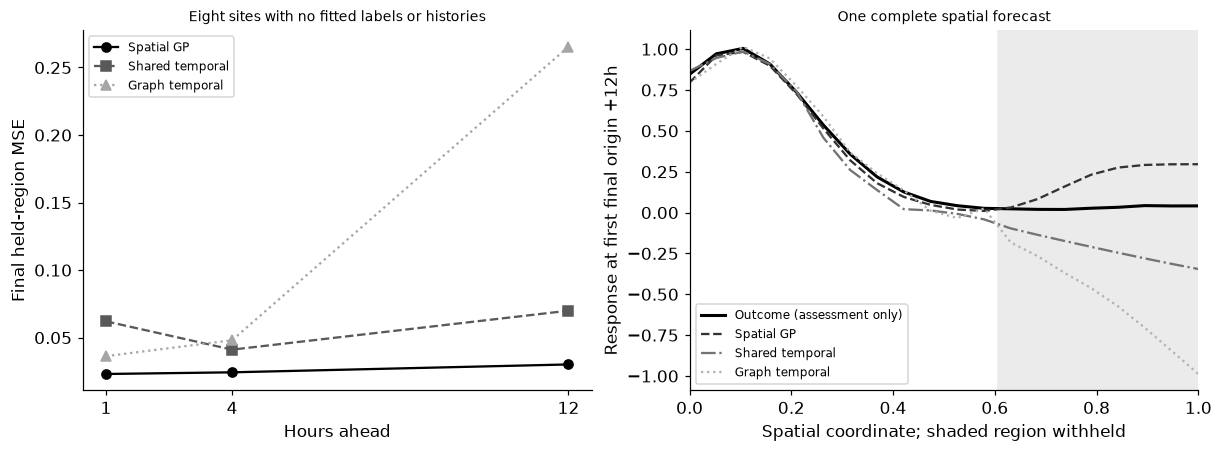

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4));styles=['o-','s--','^:'];shades=['black','.35','.65']
for (name,prediction),style,color in zip(predictions.items(),styles,shades):row=next(r for r in rows if r['model']==name and r['region']=='Held region');axes[0].plot(horizons,row['MSE_by_horizon'],style,color=color,label=name)
axes[0].set(xticks=horizons,xlabel='Hours ahead',ylabel='Final held-region MSE',title='Eight sites with no fitted labels or histories');axes[0].legend(fontsize=8)
axes[1].plot(positions,truth[0,:,-1],color='black',linewidth=2,label='Outcome (assessment only)')
for (name,prediction),style,color in zip(predictions.items(),['--','-.',':'],['.2','.45','.7']):axes[1].plot(positions,prediction[0,:,-1],style,color=color,label=name)
axes[1].axvspan((positions[11]+positions[12])/2,1.03,color='.92',zorder=0);axes[1].set(xlim=(0,1),xlabel='Spatial coordinate; shaded region withheld',ylabel='Response at first final origin +12h',title='One complete spatial forecast');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_125','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native spatial Gaussian-process reference', 'actual shared GRU and graph-GRU forecasts', 'known geometry versus unavailable regional measurements', 'common forecast origins and planned moving loads', 'source and regional horizon assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native spatial Gaussian-process reference", "actual shared GRU and graph-GRU forecasts", "known geometry versus unavailable regional measurements", "common forecast origins and planned moving loads", "source and regional horizon assessment"], "elapsed_seconds": 5.194, "example_id": "code_125", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"development_source_MSE": 0.0016715791598142194, "distance_length_scale": 0.12, "family": "Spatial GP"}, {"development_source_MSE": 0.0019860474684559354, "distance_length_scale": 0.25, "family": "Spatial GP"}, {"best_step": 400, "development_source_MSE": 0.002968043868641578, "family": "Shared temporal", "rate": 0.003}, {"best_step": 400, "development_source_MSE": 0.001148556576446204, "family": "Shared temporal", "rate": 0.01}, {"best_step": 400, "development_source_MSE": 0.0028402315341162646, "family": "Graph temporal", "rate": 0.003}, {"best_step": 390, "development_source_MSE": 0.0